<a href="https://colab.research.google.com/github/Rachel-p88/AIS-Assignment/blob/main/AIS_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week",
    "native-country", "income"
]

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?",
    skip_blank_lines=True
)

df["income"] = df["income"].str.strip().str.rstrip(".")
df = df.dropna(subset=["income"]).reset_index(drop=True)
df["income_binary"] = (df["income"] == ">50K").astype(int)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (32561, 16)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


In [ ]:
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nIncome distribution:")
display(df["income"].value_counts())

print("\nCategorical columns:")
display(df.select_dtypes(include="object").nunique().sort_values(ascending=False))

print("\nNumerical summary:")
display(df.describe().T)

duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Missing values:


,0
occupation,1843
workclass,1836
native-country,583
fnlwgt,0
education,0
education-num,0
marital-status,0
age,0
relationship,0
race,0



Income distribution:


,count
income,
<=50K,24720
>50K,7841



Categorical columns:


,0
native-country,41
education,16
occupation,14
workclass,8
marital-status,7
relationship,6
race,5
sex,2
income,2



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education-num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital-gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital-loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours-per-week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0
income_binary,32561.0,0.240810,0.427581,0.0,0.0,0.0,0.0,1.0


Duplicate rows found: 24
Shape after removing duplicates: (32537, 16)
Duplicates remaining: 0


In [ ]:
numeric_columns = df.select_dtypes(include=np.number).columns.drop("income_binary", errors="ignore")

outlier_summary = []

for column in numeric_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    outlier_summary.append({
        "Feature": column,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Potential outliers": count
    })

outlier_table = pd.DataFrame(outlier_summary)
display(outlier_table)

,Feature,Lower bound,Upper bound,Potential outliers
0,age,-2.0,78.0,142
1,fnlwgt,-60922.0,415742.0,993
2,education-num,4.5,16.5,1193
3,capital-gain,0.0,0.0,2712
4,capital-loss,0.0,0.0,1519
5,hours-per-week,32.5,52.5,9002


In [ ]:
RANDOM_STATE = 368

X = df.drop(columns=["income", "income_binary", "education"])
y = df["income_binary"]

numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=feature_names, index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed,
    columns=feature_names, index=X_test.index
)

X_train_ols = sm.add_constant(X_train_processed, has_constant="add")
X_test_ols = sm.add_constant(X_test_processed, has_constant="add")

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Training design matrix rank:", np.linalg.matrix_rank(X_train_ols))
print("Training design matrix columns:", X_train_ols.shape[1])
print("Missing values:", X_train_processed.isnull().sum().sum())

Training shape: (22775, 82)
Testing shape: (9762, 82)
Training design matrix rank: 83
Training design matrix columns: 83
Missing values: 0


In [ ]:
model_a = sm.OLS(y_train, X_train_ols).fit()

model_b = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

model_b.fit(X_train_processed, y_train)

pred_a = model_a.predict(X_test_ols)
pred_b = model_b.predict_proba(X_test_processed)[:, 1]

median_threshold = np.median(pred_a)

class_a = (pred_a >= median_threshold).astype(int)
class_b = (pred_b >= 0.5).astype(int)

comparison_matrix = confusion_matrix(class_a, class_b, labels=[0, 1])
mismatches = int(np.sum(class_a != class_b))
mismatch_percentage = mismatches / len(y_test) * 100

print("OLS median threshold:", median_threshold)
print("Mismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

display(pd.DataFrame(
    comparison_matrix,
    index=["OLS: 0", "OLS: 1"],
    columns=["Logistic: 0", "Logistic: 1"]
))

OLS median threshold: 0.23509841074102383
Mismatched cases: 2878
Mismatch percentage: 29.48 %


,Logistic: 0,Logistic: 1
OLS: 0,4876,5
OLS: 1,2873,2008


In [ ]:
analysis_df = df.copy()

numeric_cols = analysis_df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = analysis_df.select_dtypes(include="object").columns.tolist()

for col in numeric_cols:
    analysis_df[col] = analysis_df[col].fillna(analysis_df[col].median())

for col in categorical_cols:
    analysis_df[col] = analysis_df[col].fillna(analysis_df[col].mode()[0])

analysis_df = analysis_df.rename(columns={
    "education-num": "education_num",
    "hours-per-week": "hours_per_week",
    "capital-gain": "capital_gain",
    "capital-loss": "capital_loss",
    "marital-status": "marital_status"
})

formula = (
    "income_binary ~ education_num + age + hours_per_week + "
    "capital_gain + capital_loss + C(workclass) + "
    "C(marital_status) + C(race)"
)

model_full = smf.glm(
    formula=formula,
    data=analysis_df,
    family=sm.families.Binomial()
).fit()

model_male = smf.glm(
    formula=formula,
    data=analysis_df[analysis_df["sex"] == "Male"],
    family=sm.families.Binomial()
).fit()

model_female = smf.glm(
    formula=formula,
    data=analysis_df[analysis_df["sex"] == "Female"],
    family=sm.families.Binomial()
).fit()

subgroup_results = []

for name, model in [
    ("Full dataset", model_full),
    ("Male", model_male),
    ("Female", model_female)
]:
    subgroup_results.append({
        "Group": name,
        "Sample size": int(model.nobs),
        "Education coefficient": model.params["education_num"],
        "Odds ratio": np.exp(model.params["education_num"]),
        "CI lower": model.conf_int().loc["education_num", 0],
        "CI upper": model.conf_int().loc["education_num", 1],
        "p-value": model.pvalues["education_num"]
    })

subgroup_table = pd.DataFrame(subgroup_results)
display(subgroup_table.round(6))

,Group,Sample size,Education coefficient,Odds ratio,CI lower,CI upper,p-value
0,Full dataset,32537,0.361206,1.435060,0.345812,0.376601,0.0
1,Male,21775,0.351766,1.421576,0.335104,0.368428,0.0
2,Female,10762,0.430057,1.537345,0.388913,0.471201,0.0


In [ ]:
analysis_train = analysis_df.loc[X_train.index].copy()
analysis_train = analysis_train.rename(columns={"native-country": "native_country"})

numeric_ovb = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

for col in numeric_ovb:
    std = analysis_train[col].std()
    if std > 0:
        analysis_train[col] = (analysis_train[col] - analysis_train[col].mean()) / std

full_formula = "income_binary ~ age + fnlwgt + education_num + capital_gain + capital_loss + hours_per_week + C(workclass) + C(marital_status) + C(occupation) + C(relationship) + C(race) + C(sex) + C(native_country)"
reduced_formula = "income_binary ~ age + fnlwgt + education_num + capital_gain + capital_loss + hours_per_week + C(workclass) + C(occupation) + C(relationship) + C(race) + C(sex) + C(native_country)"

full_ovb = smf.glm(
    formula=full_formula,
    data=analysis_train,
    family=sm.families.Binomial()
).fit(maxiter=200)

reduced_ovb = smf.glm(
    formula=reduced_formula,
    data=analysis_train,
    family=sm.families.Binomial()
).fit(maxiter=200)

predictors = ["age", "education_num", "hours_per_week", "capital_gain"]

ovb_results = []

for predictor in predictors:
    full_coef = full_ovb.params[predictor]
    reduced_coef = reduced_ovb.params[predictor]
    absolute_change = abs(reduced_coef - full_coef)
    percentage_change = ((reduced_coef - full_coef) / abs(full_coef)) * 100 if full_coef != 0 else np.nan

    ovb_results.append({
        "Predictor": predictor,
        "Full coefficient": full_coef,
        "Reduced coefficient": reduced_coef,
        "Absolute change": absolute_change,
        "Percentage change (%)": percentage_change
    })

ovb_table = pd.DataFrame(ovb_results)
display(ovb_table)

largest_shift = ovb_table.loc[ovb_table["Absolute change"].idxmax()]

print("Largest absolute coefficient shift:", largest_shift["Predictor"])
print("Absolute shift:", largest_shift["Absolute change"])
print("Percentage change:", round(largest_shift["Percentage change (%)"], 2), "%")
print("Full model converged:", full_ovb.converged)
print("Reduced model converged:", reduced_ovb.converged)

,Predictor,Full coefficient,Reduced coefficient,Absolute change,Percentage change (%)
0,age,0.343077,0.380747,0.037669,10.979861
1,education_num,0.781083,0.773367,0.007716,-0.987904
2,hours_per_week,0.428648,0.431030,0.002381,0.555584
3,capital_gain,2.294068,2.288627,0.005441,-0.237198


Largest absolute coefficient shift: age
Absolute shift: 0.037669404291909125
Percentage change: 10.98 %
Full model converged: True
Reduced model converged: True


In [ ]:
adversarial_results = pd.DataFrame({
    "actual": np.asarray(y_test),
    "probability": np.asarray(pred_b)
}, index=y_test.index)

adversarial_results["predicted"] = (adversarial_results["probability"] >= 0.5).astype(int)

adversarial_results["error_type"] = np.select(
    [
        (adversarial_results["probability"] >= 0.75) & (adversarial_results["actual"] == 0),
        (adversarial_results["probability"] <= 0.25) & (adversarial_results["actual"] == 1)
    ],
    ["False positive", "False negative"],
    default="Not high-confidence error"
)

high_confidence_errors = adversarial_results[
    adversarial_results["error_type"] != "Not high-confidence error"
]

print("Total test examples:", len(adversarial_results))
print("High-confidence errors:", len(high_confidence_errors))
print("Percentage of test set:", round(100 * len(high_confidence_errors) / len(adversarial_results), 2), "%")
print("False positives:", (high_confidence_errors["error_type"] == "False positive").sum())
print("False negatives:", (high_confidence_errors["error_type"] == "False negative").sum())

sample_errors = high_confidence_errors.sample(
    n=min(50, len(high_confidence_errors)),
    random_state=368
)

comparison = df.loc[X_test.index].copy()
comparison["actual"] = np.asarray(y_test)
comparison["probability"] = np.asarray(pred_b)

sample_demographics = comparison.loc[sample_errors.index]
full_test_demographics = comparison

print("\nHigh-confidence error sample size:", len(sample_demographics))
print("\nAge comparison")
display(pd.DataFrame({
    "High-confidence errors": sample_demographics["age"].describe(),
    "Full test set": full_test_demographics["age"].describe()
}))

for col in ["sex", "race", "marital-status", "education-num"]:
    print(f"\n{col}: high-confidence errors")
    display((sample_demographics[col].value_counts(normalize=True) * 100).round(2).rename("Percentage"))
    print(f"{col}: full test set")
    display((full_test_demographics[col].value_counts(normalize=True) * 100).round(2).rename("Percentage"))

print("\nExamples of high-confidence errors")
display(
    sample_demographics[
        ["age", "sex", "race", "marital-status", "education-num", "hours-per-week", "capital-gain", "capital-loss", "actual", "probability"]
    ].head(10)
)

Total test examples: 9762
High-confidence errors: 485
Percentage of test set: 4.97 %
False positives: 125
False negatives: 360

High-confidence error sample size: 50

Age comparison


,High-confidence errors,Full test set
count,50.000000,9762.000000
mean,43.880000,38.633477
std,11.786606,13.621159
min,23.000000,17.000000
25%,35.250000,28.000000
50%,43.000000,37.000000
75%,51.000000,48.000000
max,73.000000,90.000000



sex: high-confidence errors


,Percentage
sex,
Male,72.0
Female,28.0


sex: full test set


...

,Percentage
education-num,
9,32.0
13,18.0
10,12.0
7,10.0
5,6.0
14,6.0
16,6.0
15,6.0
12,2.0


education-num: full test set


,Percentage
education-num,
9,32.65
10,22.13
13,16.48
14,5.19
11,4.01
7,3.66
12,3.40
6,2.84
15,1.99



Examples of high-confidence errors


,age,sex,race,marital-status,education-num,hours-per-week,capital-gain,capital-loss,actual,probability
15856,47,Male,White,Married-civ-spouse,13,30,0,2002,0,0.783655
25324,27,Female,White,Married-civ-spouse,9,40,0,0,1,0.121237
6263,42,Male,White,Married-civ-spouse,14,65,0,0,0,0.785123
17885,58,Female,White,Married-civ-spouse,9,20,0,0,1,0.221406
29168,39,Male,White,Married-civ-spouse,9,40,0,0,1,0.231767
29038,28,Male,Black,Married-civ-spouse,5,40,0,0,1,0.024459
12809,44,Female,White,Married-civ-spouse,10,40,0,0,1,0.034152
1992,47,Male,White,Never-married,10,70,0,0,1,0.176628
32081,49,Female,White,Divorced,13,40,0,0,1,0.107465
21408,60,Male,White,Married-civ-spouse,7,40,0,0,1,0.223938


In [ ]:
y_true = np.asarray(y_test)
probabilities = np.asarray(pred_b)
sex_test = df.loc[y_test.index, "sex"].to_numpy()

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

def safe_ratio(numerator, denominator):
    if denominator == 0 or np.isnan(denominator):
        return np.nan
    return numerator / denominator

fairness_results = []

for threshold in thresholds:
    predictions = (probabilities >= threshold).astype(int)

    group_metrics = {}

    for group in ["Female", "Male"]:
        mask = sex_test == group
        actual = y_true[mask]
        predicted = predictions[mask]

        positive_rate = np.mean(predicted == 1)
        true_positive_rate = np.sum((predicted == 1) & (actual == 1)) / np.sum(actual == 1) if np.sum(actual == 1) else np.nan
        false_positive_rate = np.sum((predicted == 1) & (actual == 0)) / np.sum(actual == 0) if np.sum(actual == 0) else np.nan
        predicted_positive = predicted == 1
        positive_predictive_value = np.mean(actual[predicted_positive] == 1) if np.sum(predicted_positive) else np.nan

        group_metrics[group] = {
            "DP rate": positive_rate,
            "TPR": true_positive_rate,
            "FPR": false_positive_rate,
            "PPV": positive_predictive_value
        }

    female = group_metrics["Female"]
    male = group_metrics["Male"]

    dp_ratio = safe_ratio(female["DP rate"], male["DP rate"])
    tpr_ratio = safe_ratio(female["TPR"], male["TPR"])
    fpr_ratio = safe_ratio(female["FPR"], male["FPR"])
    eo_ratio = min(tpr_ratio, fpr_ratio) if not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio) else np.nan
    pp_ratio = safe_ratio(female["PPV"], male["PPV"])

    fairness_results.append({
        "Threshold": threshold,
        "DP ratio (F/M)": dp_ratio,
        "TPR ratio (F/M)": tpr_ratio,
        "FPR ratio (F/M)": fpr_ratio,
        "EO ratio": eo_ratio,
        "PP ratio (F/M)": pp_ratio
    })

fairness_table = pd.DataFrame(fairness_results)
display(fairness_table.round(4))

,Threshold,DP ratio (F/M),TPR ratio (F/M),FPR ratio (F/M),EO ratio,PP ratio (F/M)
0,0.05,0.4568,0.9444,0.4208,0.4208,0.7409
1,0.15,0.3056,0.8287,0.2453,0.2453,0.9718
2,0.25,0.2830,0.8055,0.2150,0.2150,1.0200
3,0.35,0.2889,0.7979,0.2298,0.2298,0.9896
4,0.45,0.2772,0.7854,0.2089,0.2089,1.0153
5,0.55,0.2799,0.7881,0.2128,0.2128,1.0090
6,0.65,0.2923,0.8326,0.2095,0.2095,1.0205
7,0.75,0.3194,0.8977,0.2381,0.2381,1.0070
8,0.85,0.3294,0.8988,0.3340,0.3340,0.9778
9,0.95,0.3025,0.8412,0.2703,0.2703,0.9966


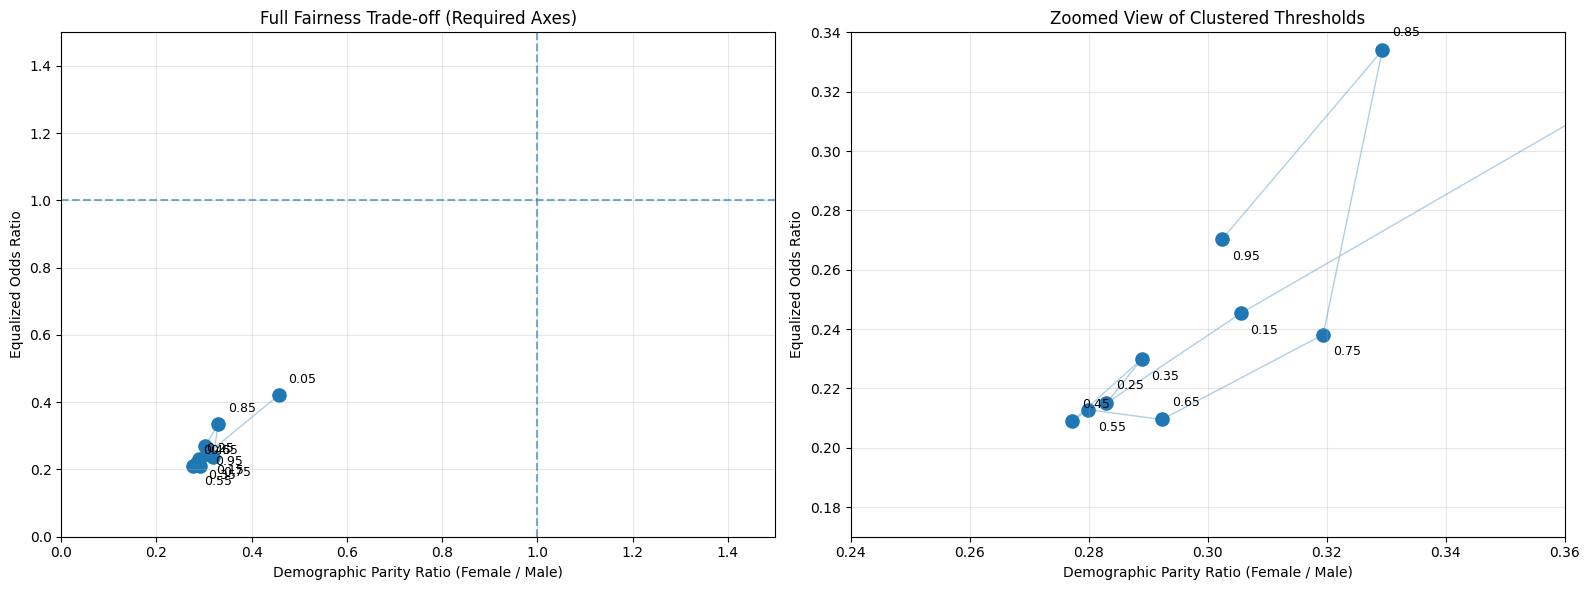

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x = fairness_table["DP ratio (F/M)"]
y = fairness_table["EO ratio"]
labels = fairness_table["Threshold"].map(lambda value: f"{value:.2f}")

axes[0].plot(x, y, alpha=0.35, linewidth=1)
axes[0].scatter(x, y, s=90)

for i, row in fairness_table.iterrows():
    if pd.notna(row["DP ratio (F/M)"]) and pd.notna(row["EO ratio"]):
        offset_y = 9 if i % 2 == 0 else -14
        axes[0].annotate(
            f'{row["Threshold"]:.2f}',
            (row["DP ratio (F/M)"], row["EO ratio"]),
            xytext=(7, offset_y),
            textcoords="offset points",
            fontsize=9
        )

axes[0].set_xlim(0, 1.5)
axes[0].set_ylim(0, 1.5)
axes[0].set_xlabel("Demographic Parity Ratio (Female / Male)")
axes[0].set_ylabel("Equalized Odds Ratio")
axes[0].set_title("Full Fairness Trade-off (Required Axes)")
axes[0].axvline(1.0, linestyle="--", alpha=0.6)
axes[0].axhline(1.0, linestyle="--", alpha=0.6)
axes[0].grid(True, alpha=0.3)

axes[1].plot(x, y, alpha=0.35, linewidth=1)
axes[1].scatter(x, y, s=90)

for i, row in fairness_table.iterrows():
    if pd.notna(row["DP ratio (F/M)"]) and pd.notna(row["EO ratio"]):
        offset_y = 10 if i % 2 == 0 else -15
        axes[1].annotate(
            f'{row["Threshold"]:.2f}',
            (row["DP ratio (F/M)"], row["EO ratio"]),
            xytext=(7, offset_y),
            textcoords="offset points",
            fontsize=9
        )

axes[1].set_xlim(0.24, 0.36)
axes[1].set_ylim(0.17, 0.34)
axes[1].set_xlabel("Demographic Parity Ratio (Female / Male)")
axes[1].set_ylabel("Equalized Odds Ratio")
axes[1].set_title("Zoomed View of Clustered Thresholds")
axes[1].axvline(1.0, linestyle="--", alpha=0.6)
axes[1].axhline(1.0, linestyle="--", alpha=0.6)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()